In [256]:
from networkx.algorithms.community import kernighan_lin_bisection
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from IPython.display import Image
from IPython.core.display import HTML

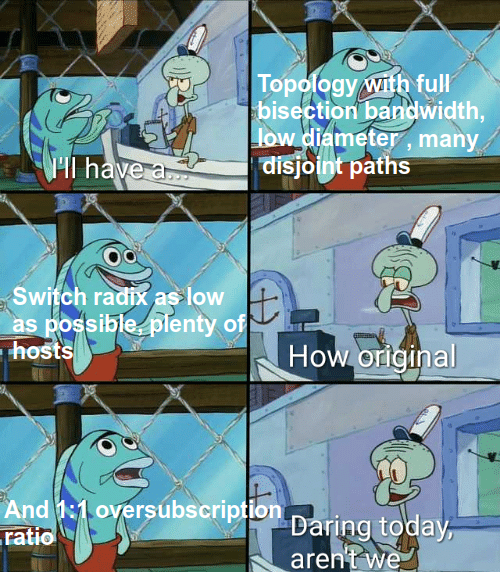

In [82]:
Image(filename = "../figs/ill_have_a.png", width=300)

What do we look for when choosing a datacenter topology?

As many hosts as possible:
- We have realistic constraints when building a topology: switch radix $k$, cost per meter of cable.
- The cable cost can be hidden behind the topology diameter $D$: ignoring hosts, what is the longest shortest path between any two switches? A lower diameter also means better latency.
- How many hosts can we fit if we can afford a radix $k$ and a diameter $D$? The Moore Bound gives an answer. There are certain topologies that are built with the specific intent on being as close as possible to this bound.

As many edge disjoint paths as possible between any two switches:
- Maximize the minimum number of edge disjoint paths between any two switches $(u, v)$. (two paths are edge disjoint if they share no common link)
- This increases the number of paths that multipath transport can exploit.
- A high disjoint path count also means better redundancy. If two paths aren't edge disjoint, a failed link on the common path means both paths are now unusable.

High or full [bisection bandwidth](https://en.wikipedia.org/wiki/Bisection_bandwidth):
- Split the $N$ hosts into two groups of $N/2$ hosts each. What is the minimum capacity of links that you need to cut such that you disconnect the two groups?
- Full bisection bandwidth doesn't necessarily mean maximizing the minimum number of edge disjoint paths. A network where all hosts are connected to the only switch has full bisection bandwidth of $N/2$, but only one edge disjoint path between any host pair.

Low oversubscription ratio against various traffic patterns:
- We want our network's Flow Completion Time (FCT) to be relatively close to an optimal network with the same number of hosts.
- The optimal network has only one switch, large enough to accomodate all hosts.
- The oversubscription ratio is the largest value the fraction between our FCT and the optimal net FCT can take over all possible traffic patterns.
- Purposely designing an oversubscribed topology can help reduce costs.

**The Moore Bound (1)**

First, let's look at the Moore Bound in its general form. Consider all graphs where each node has at most $k$ neighbours (degree $k$) and the maximum shortest path between any two nodes is $D$ (diameter $D$).

Compute an upper bound $\text{MB}(k, D)$ on the largest number of nodes such a graph can have.

*Hint: Start from a node. How many nodes can it see, respecting $k$ and $D$? Try to resemble a BFS. If stuck, consult [this](https://mathworld.wolfram.com/Degree-DiameterProblem.html).*

In [13]:
def moore_bound(k, D):
    return (k * (k-1)**D - 2) // (k-2) if k > 2\
           else 1 + 2*D

In [29]:
assert(moore_bound(k = 3, D = 2) >= 10) # https://en.wikipedia.org/wiki/Petersen_graph
assert(moore_bound(k = 2, D = 5) >= 11)

How close to the Moore Bound do we know how to build graphs? Asymptotically close it seems (as the degree increases). Article [here](https://arxiv.org/pdf/2608.03965).

**The Moore Bound (2)**

We want to use the Moore Bound for networks. If we use it in the general form, we will maximize the switch count, but we want a maximum host count instead. Using the `moore_bound` function, find the maximum host count for a given switch radix $k$ and a switch diameter $D$.

Assume that all nodes in the graph that obtains the general Moore Bound have the same degree.

*Hint: reserve $k'$ out of the $k$ neighbours of each switch for hosts. That leaves the other $k - k'$ for the general Moore Bound.*

In [30]:
def moore_bound_nets(k, D):
    return max([z * moore_bound(k - z, D) for z in range(1, k)])

In [34]:
assert(moore_bound_nets(36, 2) == 6924)
assert(moore_bound_nets(4, 3) >= 8)

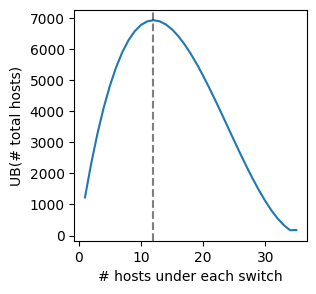

In [86]:
def plot_host_reserve(k, D):
    fig, ax = plt.subplots(1, 1, figsize = (3, 3))

    ox = range(1, k)
    oy = [z * moore_bound(k - z, D) for z in ox]
    ax.plot(ox, oy)
    
    ax.axvline(1 + np.argmax(oy), c = 'k', alpha = 0.5, ls = "--")
    
    ax.set_xlabel("# hosts under each switch")
    ax.set_ylabel("UB(# total hosts)")

plot_host_reserve(k = 36, D = 2)

**Fat trees**

Fat trees have been introduced by Charles Leiserson, the L in CLRS in the 1980s. We will discuss the original implementation, although it is no longer used for several decades. It has been superseded by an implementation detailed [here](https://www.cs.kent.edu/~javed/class-CXNET09S/papers-CXNET-2009/FaLV08-DataCenter-interconnect-p63-alfares.pdf) in 2008. Although the new implementation is a Folded Clos topology, it still retains the Fat Tree name. Variants of the new implementation were used in industry in the 2010s, e.g. in Facebook or Linkedin datacenters. See [here](https://packetpushers.net/blog/demystifying-dcn-topologies-clos-fat-trees-part2/).

Leiserson's Fat Tree is literally a tree, where either links have exponentially increasing bandwidth as they move closer to the root, or switches closer to the root have a higher radix than those closer to hosts.

- If links have exponentially increasing bandwidth, then there is an unique path between any two hosts, determined by the lowest common ancestor of the hosts.
- If all links have the same bandwidth, and the switches have exponentially bigger radii as they get closer to the root, then there are exponentially many (in the LCA depth) edge disjoint paths. However, all paths must go through the same switches. The root switch has at least as many ports as there are hosts in the network.

Leiserson's Fat Tree has full bisection bandwidth. If we note $N$ as the host count and cut the network pictured below in two sides of $N/2$ hosts each, then the capacities of the links we cut is $N/2$.
- For example, it's enough to cut the rightmost fattest link (B1),
- or the two rightmost links of immediately lower bandwidth (B2),
- or the four rightmost links of least bandwidth (B3),
- or the rightmost B2 link and two additional B3 links

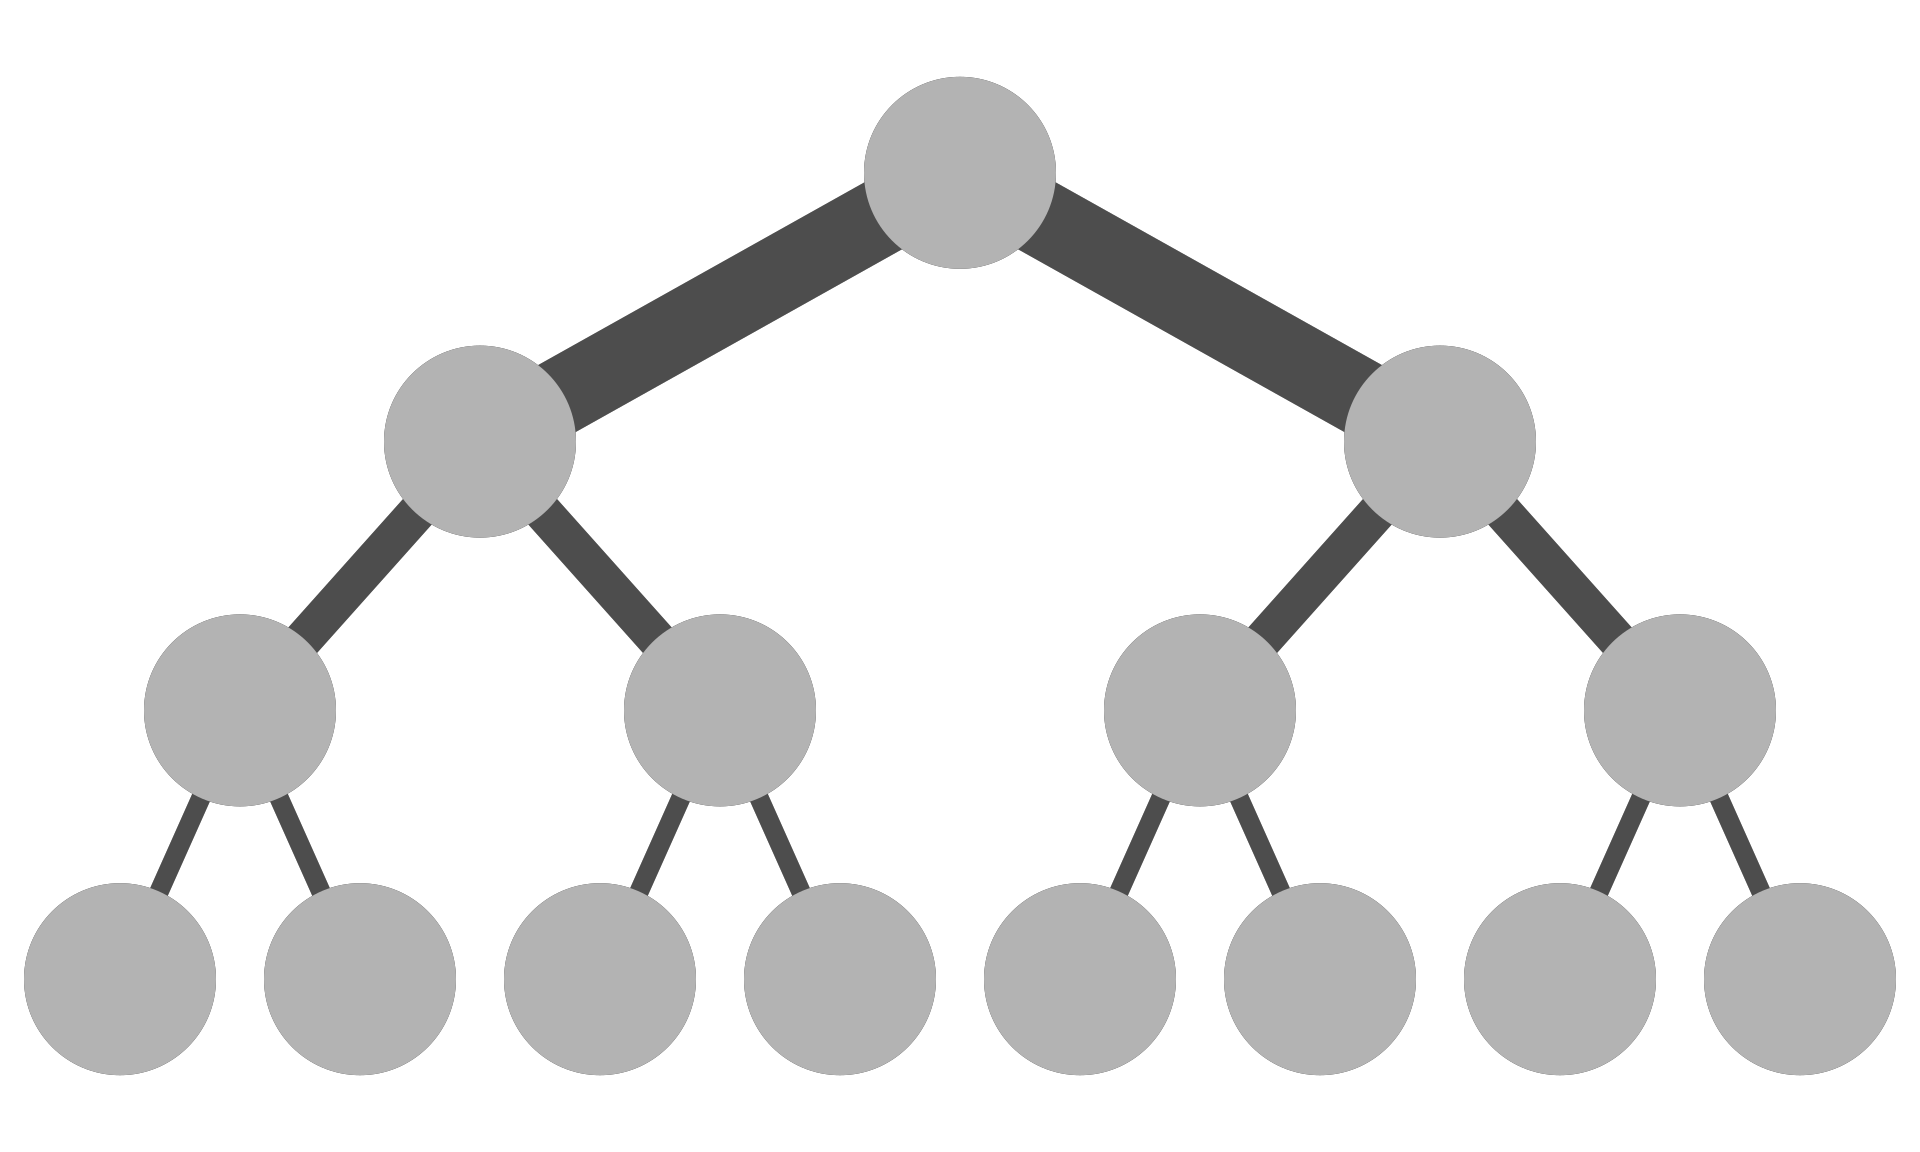

In [62]:
Image(filename = "../figs/fat_tree_leiserson.png", width=200)

A modern Fat Tree $\text{FT}(n, k)$ has two arguments, depth $n$ and switch radix $k$. The image below can be seen as a Leiserson Fat Tree at first glance. It would have depth $2$ and support $18$ hosts, while the core level switch needs $18$ ports.

- Usually, half of the Fat Tree is reversed and drawn stacked on the bottom one.
- Experiment with different values of $n$ and $k$ for $\text{FT}(n, k)$ [here](https://s3.linkmeup.ru/linkmeup/ftree/index.html).

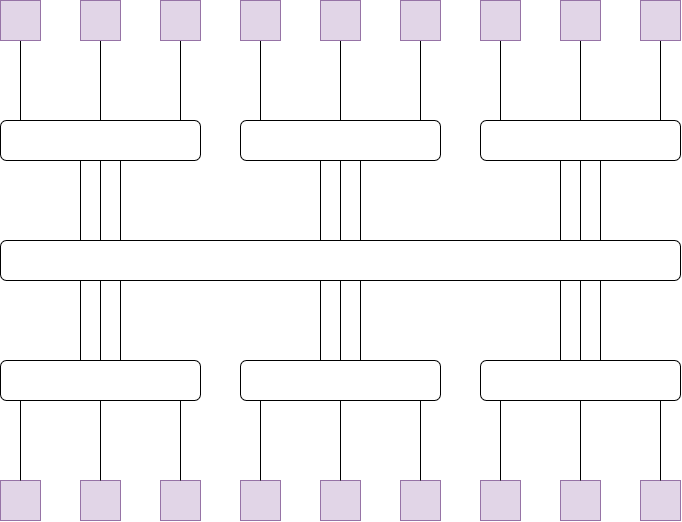

In [63]:
Image(filename = "../figs/fat_tree_virtual_lonnie.png", width=200)

However, the modern implementation regards such switches as virtual.
- There is a way to make up a depth $2$ Fat Tree that supports $18$ hosts, while only needing switches of radix $6$ instead.
- By skillfully drawing the parallel links, we can arrive in any switch making up the virtual one on any arbitrary layer.

The picture below has the radix $6$ switches drawn that make the virtual one.
- Notice that from every host there is a path to every switch, up to the Core layer.
- For any host pair $(u, v)$, let $x$ be its virtual switch least common ancestor, and $|x|$ the number of switches in $x$. Then there are $|x|$ paths from $u$ to $x$, one for each real switch. Each of the $|x|$ paths then has exactly one path down to $v$.

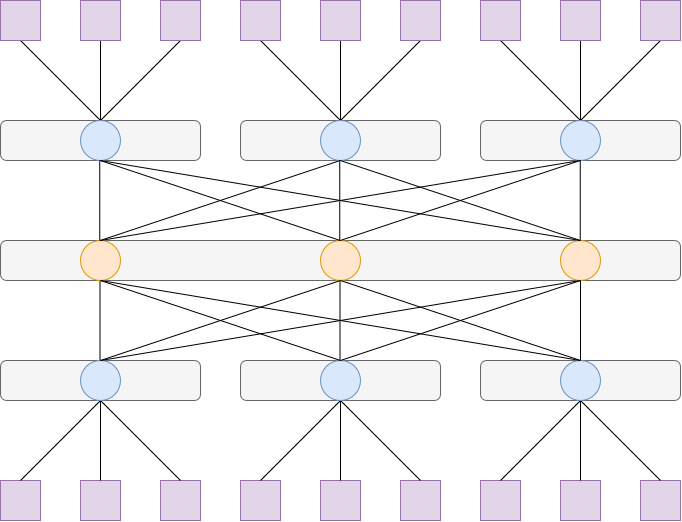

In [65]:
Image(filename = "../figs/fat_tree_lonnie_n_2_k_6.png", width=200)

If we increase the depth from $n = 2$ to $n = 3$, we can support $54$ hosts instead of $18$. See the image below.

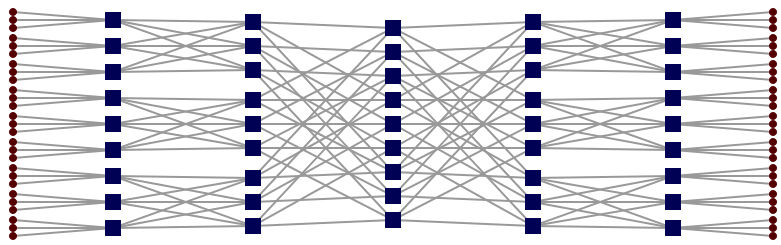

In [67]:
Image(filename = "../figs/fat_tree_lonnie_n_3_k_6.png", width=500)

**Questions**

- Experiment with the [viewer](https://s3.linkmeup.ru/linkmeup/ftree/index.html) and derive an algorithm to draw edges for $\text{FT}(n, k)$.
- Complete the functions below. For some depth $n$ and radix $k$, find the diameter of the Fat Tree network, its host count, switch count, cable count, path count between two hosts whose LCA is at depth $1 \leq x \leq n$, and bisection bandwidth.

In [ ]:
# TODO checker pentru algo care trage muchii pentru FT(n, k).

In [98]:
class FatTree:
    def __init__(self, n: int, k: int):
        self.n = n # depth
        self.k = k # switch radix
        assert(self.n >= 1)
        assert(self.k > 0 and self.k % 2 == 0)
        
    def diameter(self):
        return 2 * (self.n - 1)
    
    def host_count(self):
        return 2 * (self.k//2) ** self.n
    
    def switch_count(self):
        return (2 * self.n - 1) * (self.k//2) ** (self.n-1)
    
    def cable_count(self):
        return self.switch_count() * self.k
    
    def path_count(self, lca_depth: int):
        assert(1 <= lca_depth <= self.n)
        return (self.k//2) ** (lca_depth - 1)
    
    def bisection_bandwidth(self):
        return self.host_count() // 2

In [99]:
ft_a = FatTree(n = 3, k = 6)

assert(ft_a.diameter() == 4)
assert(ft_a.host_count() == 54)
assert(ft_a.switch_count() == 45)
assert(ft_a.cable_count() == 270)
assert(ft_a.path_count(lca_depth = 1) == 1)
assert(ft_a.path_count(lca_depth = 2) == 3)
assert(ft_a.path_count(lca_depth = 3) == 9)
assert(ft_a.bisection_bandwidth() == 27)

ft_b = FatTree(n = 3, k = 36)

assert(ft_b.host_count() == 11664)
assert(ft_b.switch_count() == 1620)
assert(ft_b.cable_count() == 58320)

**The Dragonfly Family**

The Dragonfly family is a low-diameter class of topologies. They consist of a set of virtual switches, all connected in a mesh (clique). Each virtual switch has the same number of hosts allocated to them. What differentiates members of the family is how they build the virtual switch in practice:
- `Dragonfly-` (doesn't exist in literature) simply chooses a switch radix $k$ so small that the virtual switch can be represented directly in reality.
- `Dragonfly`'s virtual switch is a layer of switches connected in a mesh, i.e. a graph in which all nodes are at distance $1$.
- `Dragonfly+`'s virtual switch is a graph in which all nodes are at distance at most $2$ from each other. Essentially, a helper layer of switches is introduced. The virtual switch layer and the helper layer form a fully bipartite graph.

You can think of other members of the family:
- `Slimfly` doesn't connect all virtual switches in a mesh. Because of this, virtual switches can have a lower degree and be represented directly as regular switches. Slimfly's defining property is that any two switches are at distance at most $2$ from each other. Slimfly is specifically chosen to be the closest graph of this kind to the Moore bound.
- What if you replace each virtual switch with a Slimfly? You keep Dragonfly+'s need of all nodes at distance at most $2$.
- What if you build further than Dragonfly+ and allow distances of at most $3$ inside each virtual switch? Can you think of a wiring that significantly increases the host count?

The layer connecting in a mesh all virtual switches (drawn in gray) in a topology from the Dragonfly family.

If we can use switches with radix at least $5$, then we we can consider the gray rectangles directly as switches, and obtain a Dragonfly- topology.

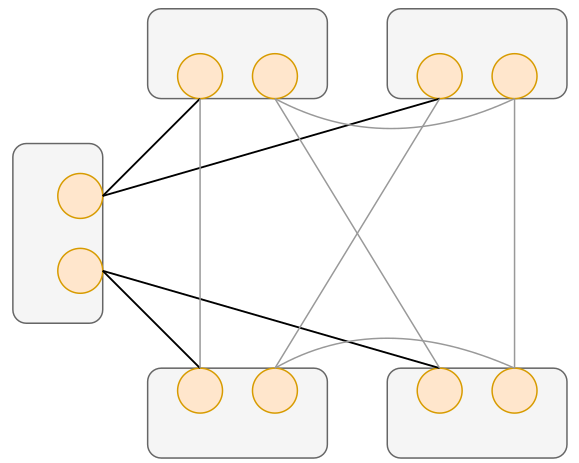

In [90]:
Image(filename = "../figs/dfly_family.png", width=200)

A Dragonfly virtual switch. We name the ensemble of virtual switch and hosts as a group. It has $p$ hosts connected to each switch and $a$ switches in each group. Here $k = 6$, $p = a = 3$. In the right part of the picture you can notice how the virtual switch operates. If a packet arrives in this group, but its destination isn't here, it may spend $0$ or $1$ hops before leaving towards the correct group.

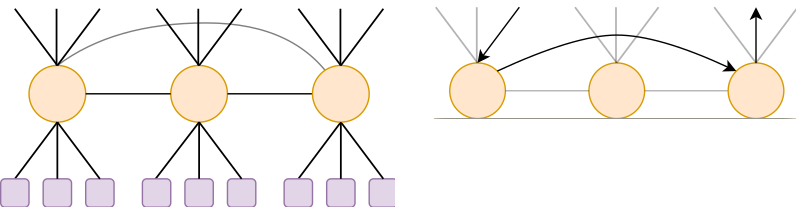

In [92]:
Image(filename = "../figs/df_virtual_switch.png", width=400)

A Dragonfly+ virtual switch. Here $p + s \leq k$, $h + l \leq k$. If a packet arrives in this group, but its destination isn't here, it may spend $0$ or $2$ hops before leaving towards the correct group. In contrast with Dragonfly, here the packet has $l$ possible ways of choosing a $2$ hop route instead of a single $1$ hop route for Dragonfly.

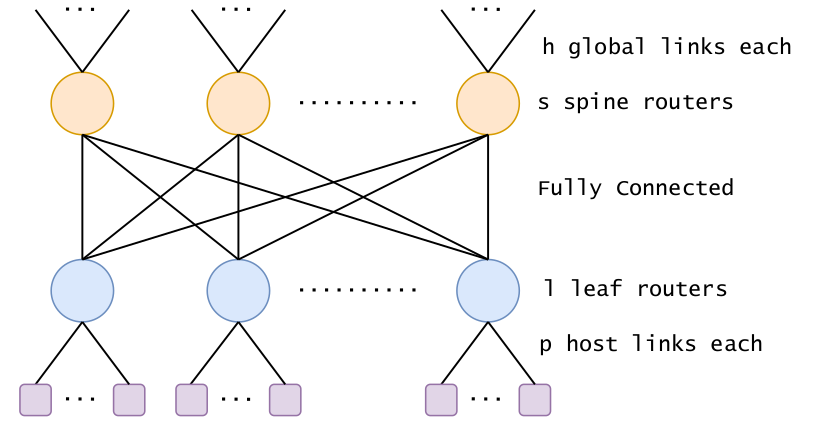

In [94]:
Image(filename = "../figs/dfp_virtual_switch.png", width=400)

The layer uniting the virtual switches is called global. There are three types of paths between hosts in different groups:
- Direct paths: the packet takes the single link connecting the two groups.
- 1-indirect paths: the packets doesn't take the link connecting the two groups. It arrives in an intermediate group. It must be able to leave to the destination group through the same switch it arrived.
- 2-indirect paths: The packet must change its spine switch to be able to leave to the destination group.

**Questions**

Consider that any two groups are connected by exactly one link. Knowing $k$ and being given:

- $p$ for Dragonfly- (it has the same meaning as for Dragonfly),
- $p$, $a$ for Dragonfly,
- $h$, $s$, $l$, $p$ for Dragonfly+.

Compute the diameter, group count, host count, switch count, cable count, the direct paths count, expected number of 1-indirect paths, expected number of 2-indirect paths. *(no bisection bandwidth for now!)*

Also, compute the maximum host count for a given $k$ in `max_host_count`.

In [192]:
class DragonflyMinus:
    def __init__(self, k: int, p: int):
        self.k = k # switch radix
        self.p = p # hosts under each switch
        self.l = k - p # global links per switch.
        assert(self.p < self.k)
        assert(self.k % 2 == 0)
        
    def diameter(self):
        return 1
    
    def group_count(self):
        return 1 + self.l
    
    def host_count(self):
        return self.group_count() * self.p
    
    def max_host_count(self):
        p_opt = self.k // 2
        return (1 + self.k - p_opt) * p_opt
    
    def switch_count(self):
        return self.group_count()
    
    def cable_count(self):
        swc = self.switch_count()
        return self.host_count() + swc * (swc-1) // 2
    
    def path_count_direct(self):
        return 1
    
    def path_count_1_indirect_expected(self):
        return self.group_count() - 2
    
    def path_count_2_indirect_expected(self):
        return 0

In [128]:
class Dragonfly:
    def __init__(self, k: int, p: int, a: int):
        self.k = k # switch radix
        self.p = p # hosts under each switch
        self.a = a # switch count in each group.
        self.l = k - p - a # global links per switch.
        assert(self.a + self.p < self.k)
        assert(self.k % 4 == 0)

    def diameter(self):
        return 3
    
    def group_count(self):
        return 1 + self.l * self.a
    
    def host_count(self):
        return self.group_count() * self.a * self.p
    
    def max_host_count(self):
        a_opt = self.k // 2
        p_opt = l_opt = self.k // 4
        return (1 + l_opt * a_opt) * a_opt * p_opt
    
    def switch_count(self):
        return self.group_count() * self.a
    
    def cable_count(self):
        # host parent links, mesh in sw virtual, strat global
        return self.host_count() +\
               self.a * (self.a - 1) // 2 +\
               self.group_count() * (self.group_count() - 1) // 2
    
    def path_count_direct(self):
        return 1
    
    def path_count_1_indirect_expected(self):
        return (self.group_count() - 2) * (self.l - 1) / (self.a * self.l - 1)
    
    def path_count_2_indirect_expected(self):
        return self.group_count() - 2 - self.path_count_1_indirect_expected()

In [121]:
class DragonflyPlus:
    def __init__(self, k: int, h: int, s: int, l: int, p: int):
        self.k = k # switch radix
        self.h = h # global links per spine switch.
        self.s = s # spine switches count
        self.l = l # leaf switches count
        self.p = p # hosts per leaf switch.
        assert(self.s + self.p <= self.k)
        assert(self.h + self.l <= self.k)
        assert(self.k % 2 == 0)

    def diameter(self):
        return 5
    
    def group_count(self):
        return 1 + self.s * self.h
    
    def host_count(self):
        return self.group_count() * self.l * self.p
    
    def max_host_count(self):
        h_opt = s_opt = l_opt = p_opt = self.k // 2
        return (1 + s_opt * h_opt) * l_opt * p_opt
    
    def switch_count(self):
        return self.group_count() * (self.s + self.l)
    
    def cable_count(self):
        # host parent links, links in sw virtual, strat global
        return self.host_count() +\
               self.s * self.l +\
               self.group_count() * (self.group_count() - 1) // 2
    
    def path_count_direct(self):
        return 1
    
    def path_count_1_indirect_expected(self):
        return (self.group_count() - 2) * (self.h - 1) / (self.h * self.s - 1)
    
    def path_count_2_indirect_expected(self):
        return (self.group_count() - 2 - self.path_count_1_indirect_expected()) * self.l

In [134]:
dm = DragonflyMinus(k = 8, p = 3)

assert(dm.diameter() == 1)
assert(dm.group_count() == 6)
assert(dm.host_count() == 18)
assert(dm.max_host_count() == 18)
assert(dm.switch_count() == 6)
assert(dm.cable_count() == 33)
assert(dm.path_count_direct() == 1)
assert(dm.path_count_1_indirect_expected() == 4)
assert(dm.path_count_2_indirect_expected() == 0)

In [142]:
df = Dragonfly(k = 8, p = 2, a = 3)

assert(df.diameter() == 3)
assert(df.group_count() == 10)
assert(df.host_count() == 60)
assert(df.max_host_count() == 72)
assert(df.switch_count() == 30)
assert(df.cable_count() == 108)
assert(df.path_count_direct() == 1)
assert(df.path_count_1_indirect_expected() == 2.0)
assert(df.path_count_2_indirect_expected() == 6.0)

df = Dragonfly(k = 36, p = 2, a = 3)
assert(df.max_host_count() == 26406)

In [125]:
dfp = DragonflyPlus(k = 36, h = 5, s = 9, l = 10, p = 12)

assert(dfp.diameter() == 5)
assert(dfp.group_count() == 46)
assert(dfp.host_count() == 5520)
assert(dfp.max_host_count() == 105300)
assert(dfp.switch_count() == 874)
assert(dfp.cable_count() == 6645)
assert(dfp.path_count_direct() == 1)
assert(dfp.path_count_1_indirect_expected() == 4.0)
assert(dfp.path_count_2_indirect_expected() == 400.0)

While Fat Trees and Dragonflies are simple to build, they are extremely inefficient with respect to Moore's bound. Topologies such as Slimfly are much more efficient, although there are few arguments for which we know how to build them. The following plots compare max host counts between Fat Trees, Dragonflies against the Moore Bound.

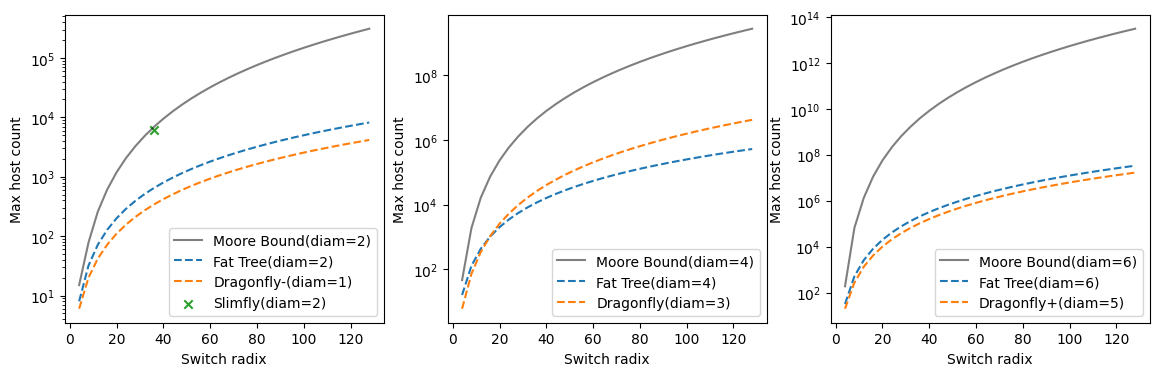

In [193]:
fig, ax = plt.subplots(1, 3, figsize = (14, 4))

ks = list(map(int, np.linspace(4, 128, 32))) # 2 ** np.arange(2, 8)

for i in range(3):
    ax[i].set_yscale("log")
    ax[i].set_xlabel("Switch radix")
    ax[i].set_ylabel("Max host count")

    ft_n = [2, 3, 4][i]
    D = 2 * (ft_n-1)
    
    ax[i].plot(ks, [moore_bound_nets(k, D) for k in ks], c = 'k', alpha = 0.5)
    ax[i].plot(ks, [FatTree(n = ft_n, k = k).host_count() for k in ks], c = "C0", ls = "--")
    
    if i == 0:
        ax[i].plot(ks, [DragonflyMinus(k, 1).max_host_count() for k in ks], c = "C1", ls = "--")
        
        ax[i].scatter([36], [6144], marker = 'x', c = "C2")
        
        leg = "Dragonfly-(diam=1)"
    elif i == 1:
        ax[i].plot(ks, [Dragonfly(k, 1, 1).max_host_count() for k in ks], c = "C1", ls = "--")
        leg = "Dragonfly(diam=3)"
    else:
        ax[i].plot(ks, [DragonflyPlus(k, 1, 1, 1, 1).max_host_count() for k in ks], c = "C1", ls = "--")
        leg = "Dragonfly+(diam=5)"

    ax[i].legend([f"Moore Bound(diam={D})", f"Fat Tree(diam={D})", leg] + (["Slimfly(diam=2)"] if i == 0 else []))

The following plots compare the topologies' efficiency in the max host setting, i.e. how many hosts do you get per cable or switch.

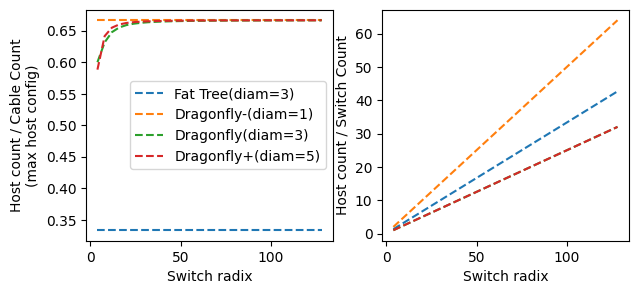

In [214]:
fig, ax = plt.subplots(1, 2, figsize = (7, 3))

ks = list(map(int, np.linspace(4, 128, 32)))

for i in range(2):
    ax[i].plot(ks, [
        ft.host_count() / (ft.cable_count() if i == 0 else ft.switch_count())
        for k in ks
        for ft in [FatTree(n = 2, k = k)]
    ], ls = "--")
    
    ax[i].plot(ks, [
        dm.host_count() / (dm.cable_count() if i == 0 else dm.switch_count())
        for k in ks
        for dm in [DragonflyMinus(k = k, p = k//2)]
    ], ls = "--")
    
    ax[i].plot(ks, [
        df.host_count() / (df.cable_count() if i == 0 else df.switch_count())
        for k in ks
        for df in [Dragonfly(k = k, p = k//4, a = k//2)]
    ], ls = "--")
    
    ax[i].plot(ks, [
        dfp.host_count() / (dfp.cable_count() if i == 0 else dfp.switch_count())
        for k in ks
        for dfp in [DragonflyPlus(k = k, h = k//2, s = k//2, l = k//2, p = k//2)]
    ], ls = "--")
    
    ax[i].set_xlabel("Switch radix")
    if i == 0:
        ax[i].legend([f"Fat Tree(diam=3)", "Dragonfly-(diam=1)", "Dragonfly(diam=3)", "Dragonfly+(diam=5)"])
        ax[i].set_ylabel("Host count / Cable Count\n(max host config)")
    else:
        ax[i].set_ylabel("Host count / Switch Count")

**Question**

*(bisection bandwidth returns)*

For a given depth $n$ and radix $k$, there is a single way of writing a Fat Tree, so a single Bisection Bandwidth value. Can the same be said about Dragonfly? The topology itself doesn't specify the way in which global links should be wired.

Analyze Dragonfly+'s Max-Host setting, with $h = s = l = p = k/2$. Compute the bisection bandwidth for the following three global wirings, over $k \in \{4, 6, 8, 10, 12\}$:

- absolute arrangement
- relative arrangement
- circulant-based arrangement

In [270]:
def arrangement(h: int, tip: str):
    cnt_groups = 1 + h**2
    cnt_sws = h * cnt_groups
    g_groups = [[] for _ in range(cnt_sws)]
    
    for i in range(cnt_groups):
        if tip == "absolute":
            oth_grs = [j for j in range(cnt_groups) if j != i]
        elif tip == "relative":
            oth_grs = [(i+1+j) % cnt_groups for j in range(cnt_groups - 1)]
        elif tip == "circulant":
            oth_grs, j, k, pin = [], (i+1) % cnt_groups, (i-1) % cnt_groups, 0
            
            while len(oth_grs) < cnt_groups - 1:
                if pin == 0:
                    oth_grs.append(j)
                    j = (j+1) % cnt_groups
                else:
                    oth_grs.append(k)
                    k = (k-1) % cnt_groups
                pin ^= 1
        else:
            assert(False)

        for z in range(h):
            g_groups[i*h + z].extend(oth_grs[z*h: (z+1)*h])
            
    edgelist = [
        (i, [x for x in range(oth_gr * h, (oth_gr+1) * h) if gr in g_groups[x]][0])
        for i in range(cnt_sws)
        for gr in [i // h]
        for oth_gr in g_groups[i]
    ]
    
    # fortez clica in grup ca sa fie tot grupul in aceeasi parte din bisectie.
    edgelist.extend([
        (i, j)
        for gr in range(cnt_groups)
        for i in range(gr*h, (gr+1)*h)
        for j in range(i+1, (gr+1)*h)
    ])

    return edgelist

In [278]:
for h in [2, 3, 4, 5]:
    ht_as = {tip: arrangement(h = h, tip = tip) for tip in ["absolute", "relative", "circulant"]}
    
    cnt_groups = 1 + h**2
    max_bis_bw = cnt_groups * (cnt_groups - 1) // 4
    
    for tip in ht_as:
        G = nx.from_edgelist(ht_as[tip])
        part_a, part_b = kernighan_lin_bisection(G, seed=42)
        bisection_bw = nx.cut_size(G, part_a, part_b)

        print(f"{h = }, {tip = }, {bisection_bw = }, {max_bis_bw = }")
    print("---")

h = 2, tip = 'absolute', bisection_bw = 5, max_bis_bw = 5
h = 2, tip = 'relative', bisection_bw = 5, max_bis_bw = 5
h = 2, tip = 'circulant', bisection_bw = 5, max_bis_bw = 5
---
h = 3, tip = 'absolute', bisection_bw = 15, max_bis_bw = 22
h = 3, tip = 'relative', bisection_bw = 21, max_bis_bw = 22
h = 3, tip = 'circulant', bisection_bw = 23, max_bis_bw = 22
---
h = 4, tip = 'absolute', bisection_bw = 44, max_bis_bw = 68
h = 4, tip = 'relative', bisection_bw = 54, max_bis_bw = 68
h = 4, tip = 'circulant', bisection_bw = 66, max_bis_bw = 68
---
h = 5, tip = 'absolute', bisection_bw = 109, max_bis_bw = 162
h = 5, tip = 'relative', bisection_bw = 149, max_bis_bw = 162
h = 5, tip = 'circulant', bisection_bw = 157, max_bis_bw = 162
---
